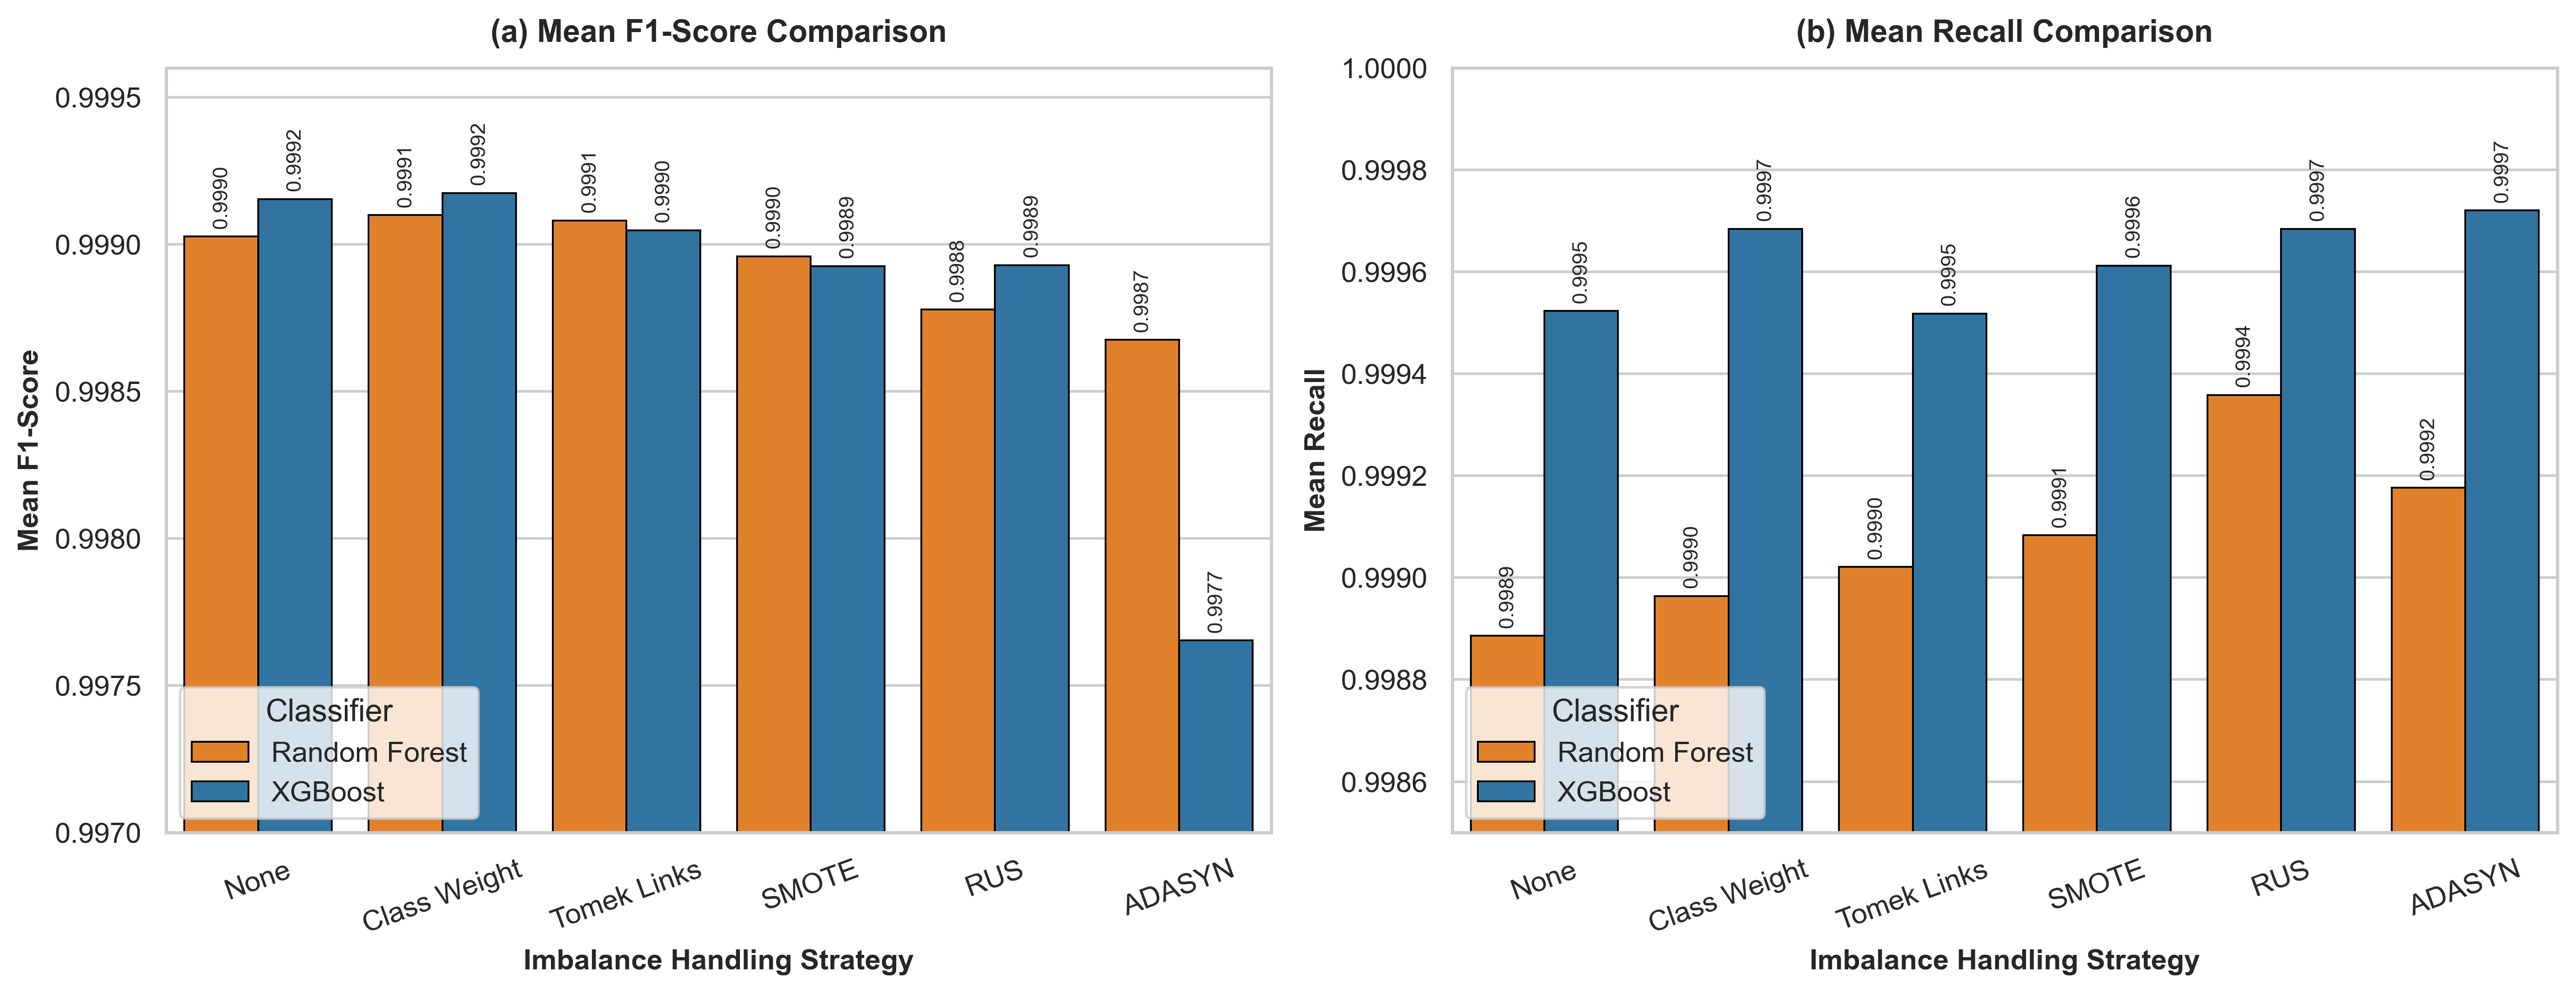

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Data diisi manual sesuai persis dengan Tabel 1 & Tabel 2 hasil eksperimen Anda
data = {
    "Handling": [
        "None",
        "Class Weight",
        "Tomek Links",
        "SMOTE",
        "RUS",
        "ADASYN",
    ]
    * 2,
    "Classifier": ["Random Forest"] * 6 + ["XGBoost"] * 6,
    "F1": [
        0.999026,
        0.999099,
        0.999081,
        0.998959,
        0.998778,
        0.998675,  # RF
        0.999153,
        0.999174,
        0.999047,
        0.998926,
        0.998929,
        0.997653,  # XGBoost
    ],
    "Recall": [
        0.998886,
        0.998964,
        0.999021,
        0.999083,
        0.999358,
        0.999176,  # RF
        0.999523,
        0.999684,
        0.999518,
        0.999612,
        0.999684,
        0.999720,  # XGBoost
    ],
    "Precision": [
        0.999166,
        0.999233,
        0.999140,
        0.998835,
        0.998200,
        0.998173,  # RF
        0.998784,
        0.998665,
        0.998577,
        0.998241,
        0.998174,
        0.995595,  # XGBoost
    ],
    "Time": [
        162.67,
        156.05,
        152.39,
        303.80,
        52.47,
        283.27,  # RF (detik)
        22.46,
        22.57,
        22.73,
        33.75,
        10.75,
        33.02,  # XGBoost (detik)
    ],
}

df_plot = pd.DataFrame(data)

# Mengatur gaya visualisasi standar publikasi jurnal
plt.rcParams["font.family"] = "serif"
sns.set_theme(style="whitegrid")

# Membuat Figure dengan 2 Panel (Atas: F1-Score, Bawah: Recall vs Precision Trade-off)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=400)

palette_colors = {"XGBoost": "#1f77b4", "Random Forest": "#ff7f0e"}

# --- PANEL (a): F1-Score Comparison ---
ax1 = sns.barplot(
    data=df_plot,
    x="Handling",
    y="F1",
    hue="Classifier",
    palette=palette_colors,
    ax=axes[0],
    edgecolor="black",
    linewidth=0.7,
)
ax1.set_ylim(0.9970, 0.9996)  # Zoomed-in agar perbedaan terlihat jelas
ax1.set_title(
    "(a) Mean F1-Score Comparison", fontsize=12, fontweight="bold", pad=10
)
ax1.set_xlabel("Imbalance Handling Strategy", fontsize=11, fontweight="bold")
ax1.set_ylabel("Mean F1-Score", fontsize=11, fontweight="bold")
ax1.tick_params(axis="x", rotation=20)
ax1.legend(title="Classifier", loc="lower left", frameon=True)

# Menambahkan label angka di atas batang Panel (a)
for container in ax1.containers:
    ax1.bar_label(container, fmt="%.4f", padding=3, fontsize=8, rotation=90)

# --- PANEL (b): Recall Comparison ---
ax2 = sns.barplot(
    data=df_plot,
    x="Handling",
    y="Recall",
    hue="Classifier",
    palette=palette_colors,
    ax=axes[1],
    edgecolor="black",
    linewidth=0.7,
)
ax2.set_ylim(0.9985, 1.0000)  # Zoomed-in untuk melihat keunggulan Recall
ax2.set_title(
    "(b) Mean Recall Comparison", fontsize=12, fontweight="bold", pad=10
)
ax2.set_xlabel("Imbalance Handling Strategy", fontsize=11, fontweight="bold")
ax2.set_ylabel("Mean Recall", fontsize=11, fontweight="bold")
ax2.tick_params(axis="x", rotation=20)
ax2.legend(title="Classifier", loc="lower left", frameon=True)

# Menambahkan label angka di atas batang Panel (b)
for container in ax2.containers:
    ax2.bar_label(container, fmt="%.4f", padding=3, fontsize=8, rotation=90)

plt.tight_layout()

# Simpan otomatis dengan resolusi 400 DPI (bebas tombol UI screenshot)
plt.savefig("Figure_Performance_Comparison.png", dpi=400, bbox_inches="tight")
plt.show()

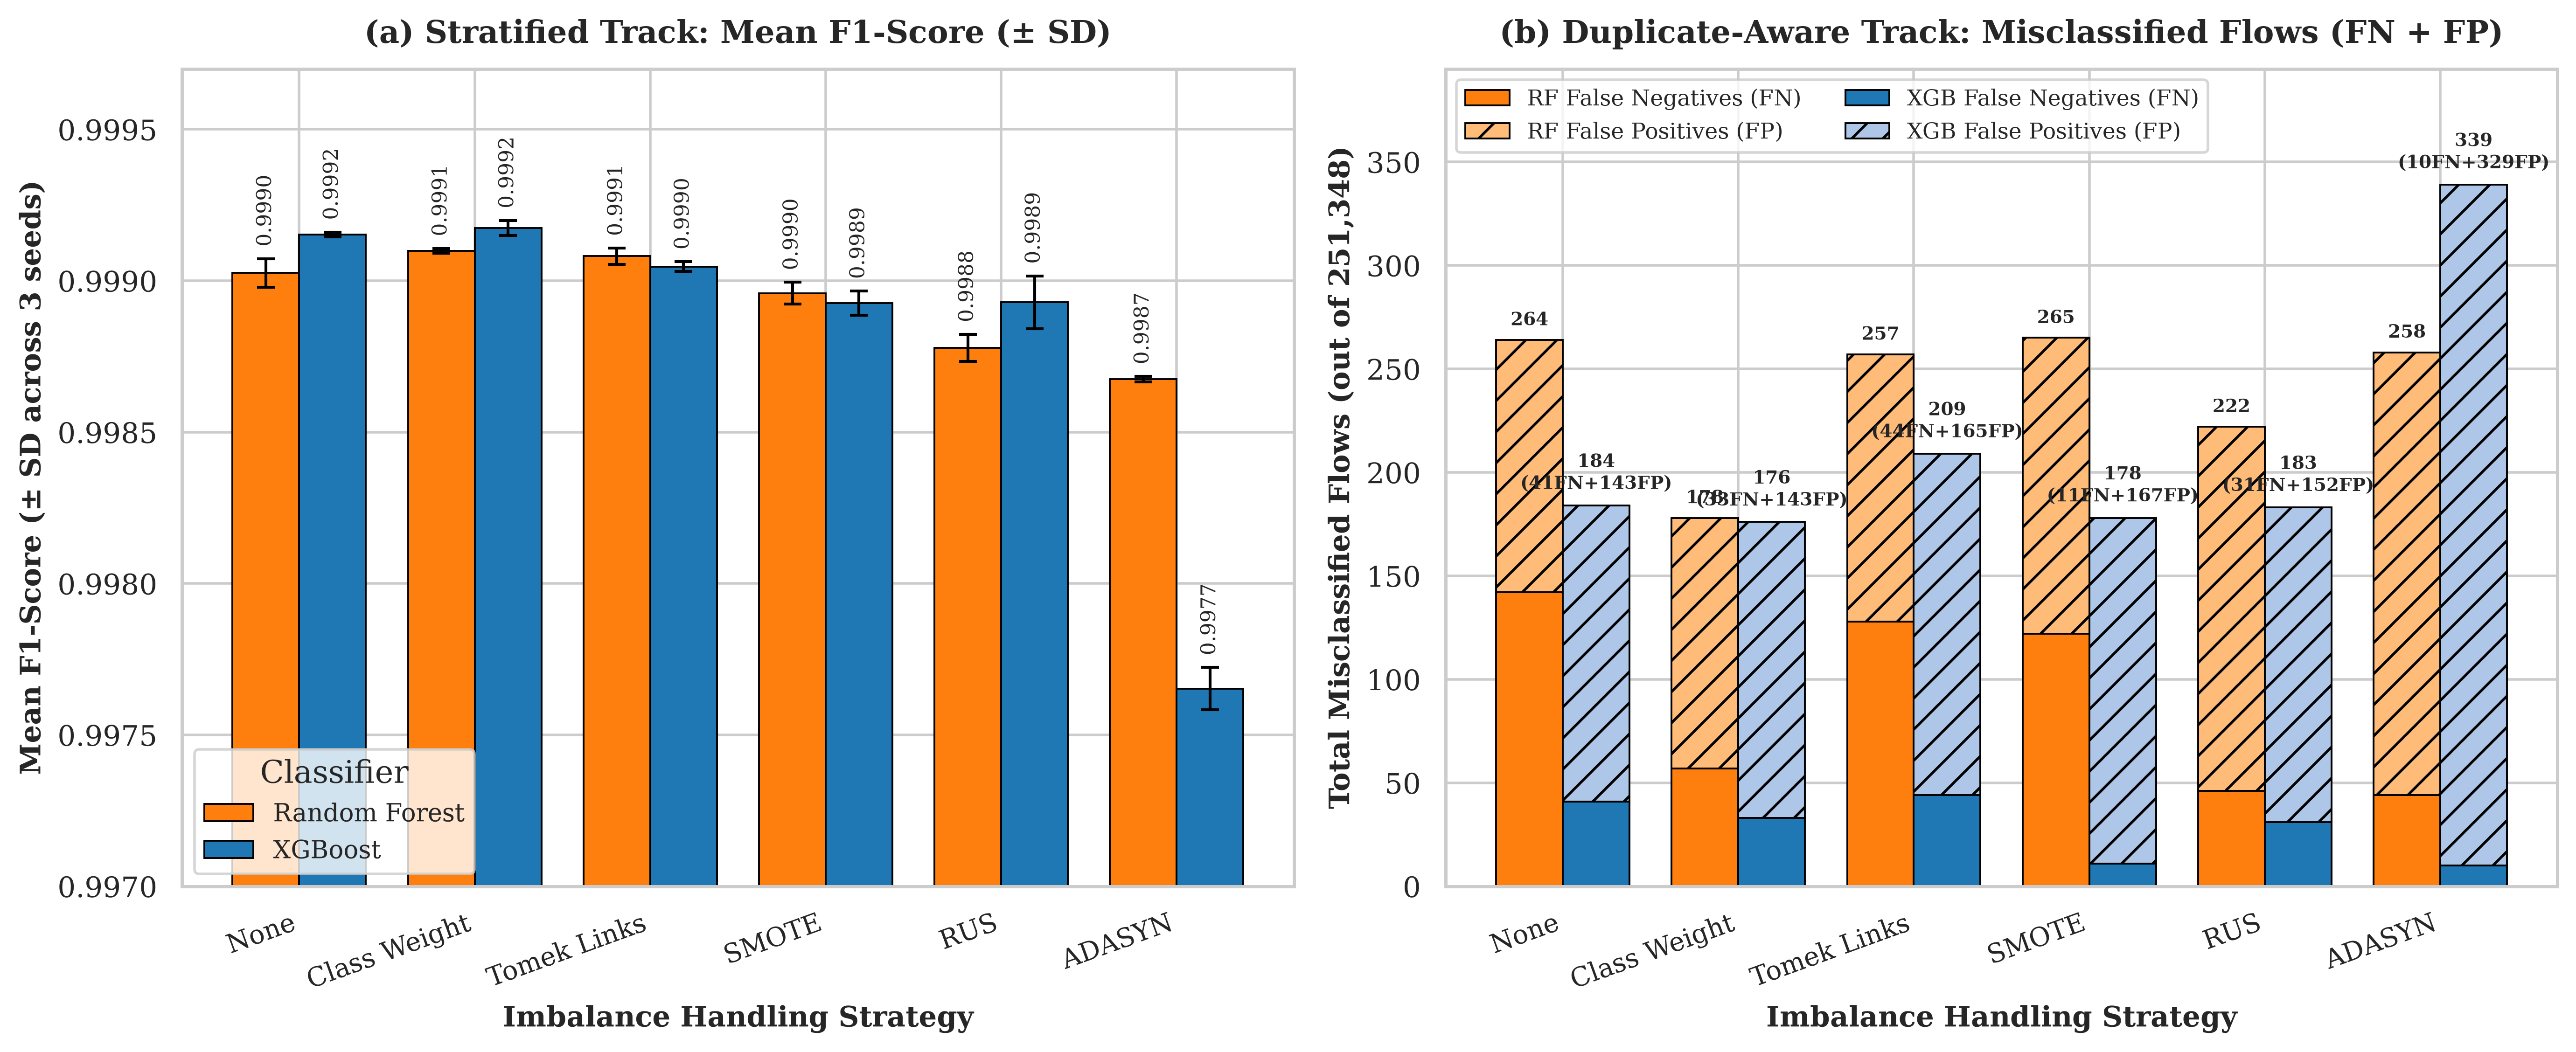

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Data sesuai persis dengan Tabel 2 (Stratified 3 seeds) & Tabel 6 (Duplicate-Aware Fold 2)
strategies = [
    "None",
    "Class Weight",
    "Tomek Links",
    "SMOTE",
    "RUS",
    "ADASYN",
]

# Data Panel (a): Stratified Mean F1-Score & Standard Deviation (SD) dari Tabel 2
rf_f1 = [0.999026, 0.999099, 0.999081, 0.998959, 0.998778, 0.998675]
rf_f1_sd = [0.000047, 0.000008, 0.000027, 0.000036, 0.000045, 0.000009]

xgb_f1 = [0.999153, 0.999174, 0.999047, 0.998926, 0.998929, 0.997653]
xgb_f1_sd = [0.000008, 0.000025, 0.000016, 0.000040, 0.000087, 0.000070]

# Data Panel (b): Duplicate-Aware Absolute Error Counts (FN & FP) dari Tabel 6 (N_test = 251,348)
rf_fn = [142, 57, 128, 122, 46, 44]
rf_fp = [122, 121, 129, 143, 176, 214]

xgb_fn = [41, 33, 44, 11, 31, 10]
xgb_fp = [143, 143, 165, 167, 152, 329]

# Mengatur gaya visualisasi standar publikasi jurnal
plt.rcParams["font.family"] = "serif"
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "serif"  # Memastikan font serif tetap aktif setelah set_theme

fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), dpi=400)

x = np.arange(len(strategies))
width = 0.38

# Warna konsisten dengan grafik asli Anda
color_rf = "#ff7f0e"
color_xgb = "#1f77b4"

# ==============================================================================
# PANEL (a): Mean F1-Score Comparison with Error Bars (± SD)
# ==============================================================================
ax1 = axes[0]
rects_rf = ax1.bar(
    x - width / 2,
    rf_f1,
    width,
    yerr=rf_f1_sd,
    capsize=3.5,
    label="Random Forest",
    color=color_rf,
    edgecolor="black",
    linewidth=0.7,
    error_kw=dict(lw=1.1, capthick=1.1, ecolor="black"),
)
rects_xgb = ax1.bar(
    x + width / 2,
    xgb_f1,
    width,
    yerr=xgb_f1_sd,
    capsize=3.5,
    label="XGBoost",
    color=color_xgb,
    edgecolor="black",
    linewidth=0.7,
    error_kw=dict(lw=1.1, capthick=1.1, ecolor="black"),
)

ax1.set_ylim(0.9970, 0.9997)
ax1.set_title(
    "(a) Stratified Track: Mean F1-Score (± SD)",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax1.set_xlabel("Imbalance Handling Strategy", fontsize=11, fontweight="bold")
ax1.set_ylabel("Mean F1-Score (± SD across 3 seeds)", fontsize=11, fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(strategies, rotation=20, ha="right", fontsize=10)
ax1.legend(title="Classifier", loc="lower left", frameon=True, fontsize=9.5)

# Menambahkan label angka tepat di atas batas atas error bar Panel (a)
for i in range(len(strategies)):
    ax1.text(
        x[i] - width / 2,
        rf_f1[i] + rf_f1_sd[i] + 0.00004,
        f"{rf_f1[i]:.4f}",
        ha="center",
        va="bottom",
        fontsize=8,
        rotation=90,
    )
    ax1.text(
        x[i] + width / 2,
        xgb_f1[i] + xgb_f1_sd[i] + 0.00004,
        f"{xgb_f1[i]:.4f}",
        ha="center",
        va="bottom",
        fontsize=8,
        rotation=90,
    )

# ==============================================================================
# PANEL (b): Duplicate-Aware Absolute FN & FP Error Counts (Stacked Bar)
# ==============================================================================
ax2 = axes[1]

# Stacked Bar untuk Random Forest (FN solid di bawah, FP berarsir di atas)
ax2.bar(
    x - width / 2,
    rf_fn,
    width,
    label="RF False Negatives (FN)",
    color="#ff7f0e",
    edgecolor="black",
    linewidth=0.7,
)
ax2.bar(
    x - width / 2,
    rf_fp,
    width,
    bottom=rf_fn,
    label="RF False Positives (FP)",
    color="#ffbb78",
    edgecolor="black",
    linewidth=0.7,
    hatch="//",
)

# Stacked Bar untuk XGBoost (FN solid di bawah, FP berarsir di atas)
ax2.bar(
    x + width / 2,
    xgb_fn,
    width,
    label="XGB False Negatives (FN)",
    color="#1f77b4",
    edgecolor="black",
    linewidth=0.7,
)
ax2.bar(
    x + width / 2,
    xgb_fp,
    width,
    bottom=xgb_fn,
    label="XGB False Positives (FP)",
    color="#aec7e8",
    edgecolor="black",
    linewidth=0.7,
    hatch="//",
)

ax2.set_ylim(0, 395)
ax2.set_title(
    "(b) Duplicate-Aware Track: Misclassified Flows (FN + FP)",
    fontsize=12,
    fontweight="bold",
    pad=10,
)
ax2.set_xlabel("Imbalance Handling Strategy", fontsize=11, fontweight="bold")
ax2.set_ylabel("Total Misclassified Flows (out of 251,348)", fontsize=11, fontweight="bold")
ax2.set_xticks(x)
ax2.set_xticklabels(strategies, rotation=20, ha="right", fontsize=10)
ax2.legend(loc="upper left", frameon=True, fontsize=8.5, ncol=2)

# Menambahkan label total error (FN + FP) di atas setiap batang Panel (b)
for i in range(len(strategies)):
    tot_rf = rf_fn[i] + rf_fp[i]
    tot_xgb = xgb_fn[i] + xgb_fp[i]
    ax2.text(
        x[i] - width / 2,
        tot_rf + 5,
        f"{tot_rf}",
        ha="center",
        va="bottom",
        fontsize=7,
        fontweight="bold",
    )
    ax2.text(
        x[i] + width / 2,
        tot_xgb + 5,
        f"{tot_xgb}\n({xgb_fn[i]}FN+{xgb_fp[i]}FP)",
        ha="center",
        va="bottom",
        fontsize=7,
        fontweight="bold",
    )

plt.tight_layout()

# Simpan otomatis dengan resolusi 400 DPI
plt.savefig("Figure_Performance_Comparison_Revised.png", dpi=400, bbox_inches="tight")
plt.show()